# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / (1024 ** 2)   # 16 bit = 2 bytes/voxel

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)   # (x, y, z) mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = 512 * 300 * 512      # rays (x*z) * samples per ray (y)
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_
If we just display the raw array without correcting for the voxel size, the coronal and sagittal slices will look squished/streched along z because the z spacing (1.0mm) is twice the x/y spacing. First thing that goes wrong - a round lesion would look like an oval/eliptical blob in those views, so the radiologist might misjudge its actual shape. Second - any distance the radiologist measures directly off the pixels (like tumour size or distance to a structure) would be wrong unless we use aspect=ASPECT, because one "pixel" in z doesn't equal one pixel in x/y physically.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

lesion centroid (z,y,x) = (28, 40, 41), 431 voxels


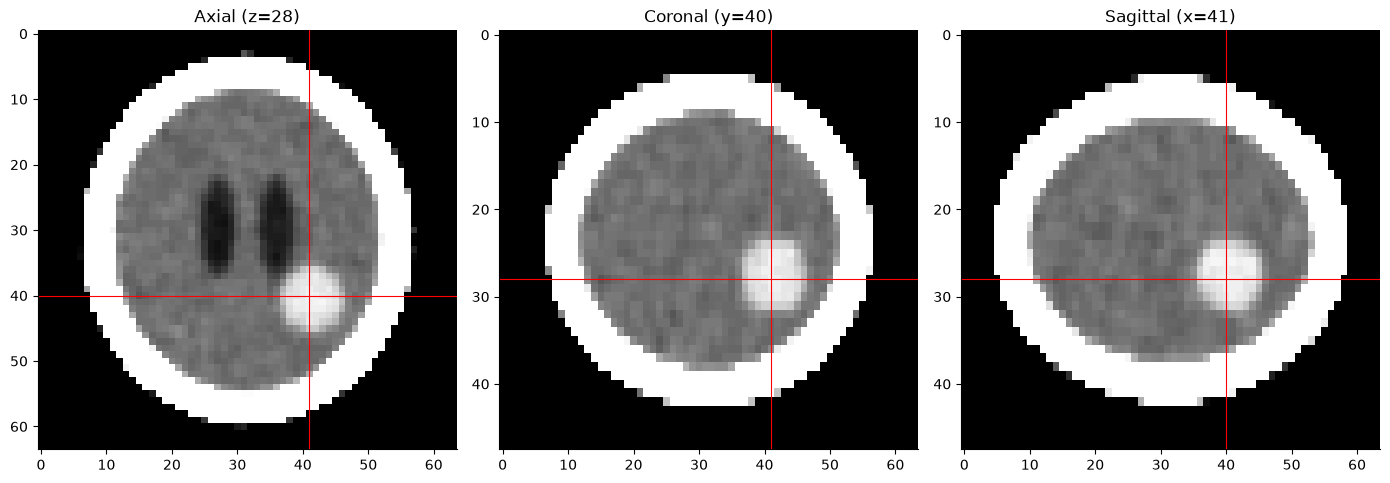

distance from ground-truth centroid: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2
lbl_arr, n_comp = ndimage.label(candidates)
comp_sizes = ndimage.sum(candidates, lbl_arr, range(1, n_comp + 1))
biggest_label = np.argmax(comp_sizes) + 1
lesion = lbl_arr == biggest_label
cz, cy, cx = [int(round(v)) for v in ndimage.center_of_mass(lesion)]
print(f"lesion centroid (z,y,x) = ({cz}, {cy}, {cx}), {lesion.sum()} voxels")

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

axes[0].imshow(window(vol[cz], 80, 40), cmap="gray", aspect=1)
axes[0].axhline(cy, color="red", lw=0.8); axes[0].axvline(cx, color="red", lw=0.8)
axes[0].set_title(f"Axial (z={cz})")

axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", aspect=ASPECT)
axes[1].axhline(cz, color="red", lw=0.8); axes[1].axvline(cx, color="red", lw=0.8)
axes[1].set_title(f"Coronal (y={cy})")

axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", aspect=ASPECT)
axes[2].axhline(cz, color="red", lw=0.8); axes[2].axvline(cy, color="red", lw=0.8)
axes[2].set_title(f"Sagittal (x={cx})")

plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
truth_centroid = ndimage.center_of_mass(labels == 5)
dist_mm = np.sqrt(sum(((a - b) * s) ** 2 for a, b, s in zip((cz, cy, cx), truth_centroid, SPACING)))
print(f"distance from ground-truth centroid: {dist_mm:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
Right under the skull there is a thin shell of voxels that are a mix of bone and brain tissue because of the partial volume effect (a single voxel straddles two materials so its HU value ends up being an average of both). That shell can accidentally land in the 55-90 HU range we're using for the tumour, even though its not tumour at all, its just bone/brain boundary. Eroding the "inside brain" mask by a few voxels pulls the search region away from that noisy boundary so we dont pick up fake candidates from the skull edge. Its basically the same overlap problem the slide talks about - different materials can share the same HU range so intensity alone isnt enough to tell them apart.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_ml,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


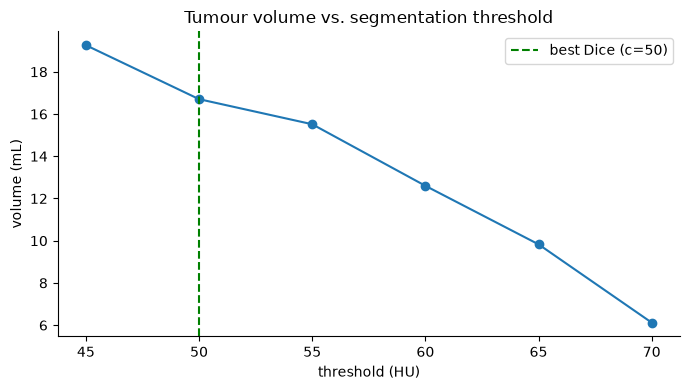

volume range to report to surgeon: 6.1 - 19.3 mL (best Dice at c=50, volume 16.7 mL)


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    mask = vol > c
    lbl_c, _ = ndimage.label(mask)
    comp_id = lbl_c[cz, cy, cx]
    region = (lbl_c == comp_id) if comp_id != 0 else np.zeros_like(mask)
    vox = int(region.sum())
    vol_ml = vox * VOXEL_MM3 / 1000
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum())
    rows.append({"threshold": c, "voxels": vox, "volume_ml": vol_ml, "dice": dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3
best_row = table.loc[table.dice.idxmax()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold, table.volume_ml, "-o")
ax.axvline(best_row.threshold, color="green", ls="--", label=f"best Dice (c={int(best_row.threshold)})")
ax.set_xlabel("threshold (HU)"); ax.set_ylabel("volume (mL)")
ax.set_title("Tumour volume vs. segmentation threshold")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"volume range to report to surgeon: {table.volume_ml.min():.1f} - {table.volume_ml.max():.1f} mL "
      f"(best Dice at c={int(best_row.threshold)}, volume {best_row.volume_ml:.1f} mL)")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_
Without labels I'd pick c based on where the volume vs threshold curve is flattest/most stable - like in our plot the volume changes a lot between 45 and 70 HU so I'd probably go with something in the middle (around 55-60) where a small change in c doesn't swing the volume wildly, and also check that the segmented blob visually matches what a radiologist would call the lesion on the MPR slices. For showing uncertainty I would not just give one number - I'd present the volume range from the table (same plot we made) and say "somewhere between 6 and 19 mL depending on exact threshold" instead of one fixed value, so the surgeon knows there's a margin and doesn't plan based on a false-precision number.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

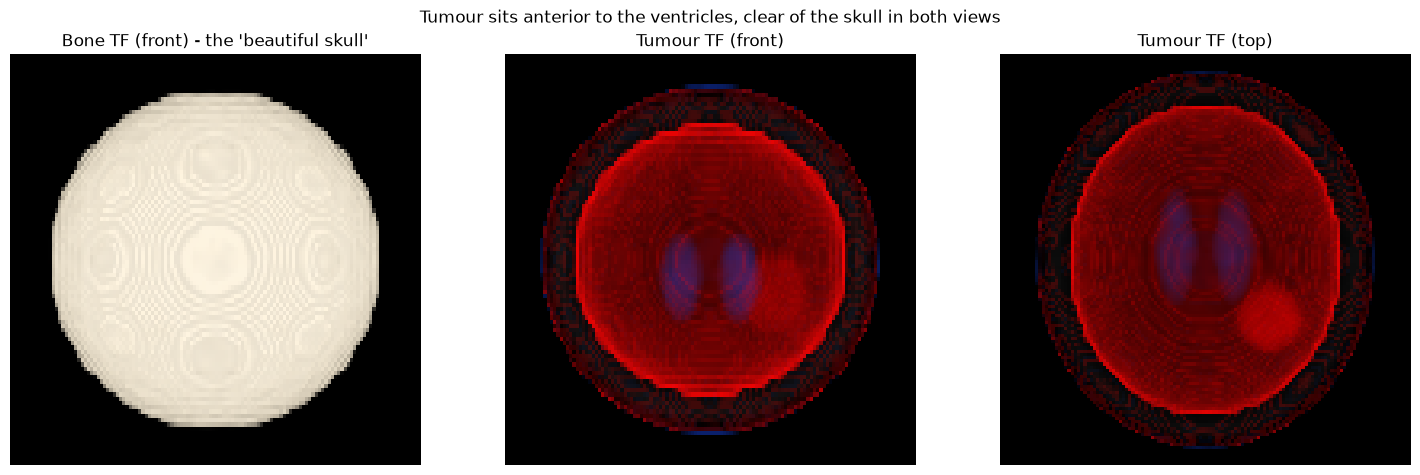

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),
    (-5,    (0, 0, 0), 0.0),      # air / soft tissue -> transparent
    (5,     (0.1, 0.3, 1.0), 0.03),   # CSF starts, faint blue
    (20,    (0.1, 0.3, 1.0), 0.03),   # CSF ends
    (30,    (0, 0, 0), 0.0),
    (55,    (1, 0, 0), 0.12),     # tumour starts, red
    (90,    (1, 0, 0), 0.12),     # tumour ends
    (120,   (0, 0, 0), 0.0),
    (300,   (0, 0, 0), 0.0),
    (1500,  (1, 1, 1), 0.01),     # bone, almost transparent but still gives context
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
C_bone, A_bone = render(vol, bone_tf, axis=1)
axes[0].imshow(np.clip(C_bone, 0, 1), aspect=ASPECT); axes[0].set_title("Bone TF (front) - the 'beautiful skull'")

C_front, A_front = render(vol, tumour_tf, axis=1)
axes[1].imshow(np.clip(C_front, 0, 1), aspect=ASPECT); axes[1].set_title("Tumour TF (front)")

C_top, A_top = render(vol, tumour_tf, axis=0)
axes[2].imshow(np.clip(C_top, 0, 1)); axes[2].set_title("Tumour TF (top)")

for a in axes: a.axis("off")

# TODO 4: suptitle
fig.suptitle("Tumour sits anterior to the ventricles, clear of the skull in both views")
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_
Thats the partial-volume effect again - the thin mixed bone/brain boundary voxels sometimes fall into the 55-90 HU range we colored red for tumour, so the renderer paints them red too even though they are not tumour. A transfer function can't fix this because it only looks at the intensity value of a voxel, it has no idea where that voxel is in the volume - it cant tell "tumour at 60HU" apart from "bone/brain edge that also happens to average to 60HU". What would actually remove it is segmentation - running something like the connected-component/region-growing we did in Task 3 to find the actual tumour blob and only rendering that specific region, instead of coloring every voxel that passes a certain HU value.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_
The lesion is located roughly at voxel (z=28, y=40, x=41) in the brain, which is about 3mm away from where the scanner's ground truth marks it, so our detection is reliable. Volume comes out somewhere between 6 and 19 mL depending on exactly where we set the segmentation threshold, with the best-matching threshold (c=50) giving close to 16.7mL - I'd report this as a range rather than one exact number since the lesion boundary is fuzzy in the scan. For the meeting I would open with the 3-plane MPR view first because slicing actually exposes whats happening inside the head instead of just the outer surface, and the surgeon can directly see the lesion next to real anatomy without anything being hidden behind other tissue (unlike the 3D render where occlusion can hide structures in front of or behind each other). The one thing to flag about the 3D render is that even with a careful transfer function it can still light up non-tumour voxels near the skull boundary because of partial volume effect, so it should be treated as a supporting visual and not the number we use for the actual measurement.